![WEkEO by Copernicus and Partners](https://github.com/wekeo/frameworks/blob/main/img/WEkEO_banner_EUMETSAT.png?raw=true)

Copyright (c) 2024 European Union 

License: MIT

# Extraction of pixel values from a Sentinel-3 satellite image

**This notebook can be run on the WEkEO JupyterHub. You can also view it on GitHub.**

[![launch-WEKEO](https://img.shields.io/badge/launch-WEKEO-1a4696.svg)](https://jupyterhub.prod.wekeo2.eu/hub/user-redirect/lab/tree/public/wekeo4data/wekeo-eocanvas/EOCanvasWorkflow_Extract_Pixel_Values.ipynb)
[![github](https://img.shields.io/badge/Open%20in-GitHub-black?logo=github)](https://github.com/wekeo/wekeo-eocanvas/blob/main/EOCanvasWorkflow_Extract_Pixel_Values.ipynb)

**PREREQUISITES**

This notebook has the following prerequisites:
- [A WEkEO account](https://my.wekeo.eu/user-registration)
- basic knowledge of EOCanvas through executing the [EOCanvas Introduction Notebook](https://github.com/wekeo/wekeo4data/blob/main/wekeo-eocanvas/01_Introduction_to_EOCanvas.ipynb)

**LEARNING OUTCOMES**

At the end of this notebook you will know:

- how to how to extract the picel values using EOCanvas
- how to modify the EOCanvas workflow to extract values from custom locations
- how to visualize the extracted values on a map

**CONTENTS**

1. [Setting up](#1-setting-up)  
2. [Retrieval of the satellite image](#2-retrieval-of-the-satellite-image)  
3. [Import / define your sampling points](#3-import--define-your-sampling-points)  
4. [Adapt the SNAP graph with your sampling points](#4-adapt-the-snap-graph-with-your-sampling-points)  
5. [Pixel extraction using EOCanvas](#5-pixel-extraction-using-eocanvas)  
6. [Post processing and visualizing the result](#6-post-processing-and-visualizing-the-result)  
7. [Take home messages](#7-take-home-messages)

<hr>

This notebook demonstrates how to access and process Sentinel-3 OLCI satellite imagery to extract pixel values for point sampling using the WEkEO EOCanvas. The sampling of pixel values is specifically useful for the generation of machine learning training datasets or for creating time series of a single point.

## 1. Setting up

Install eocanvas to your environment.

In [ ]:
! pip install -q eocanvas

Load necessary modules:

In [5]:
from eocanvas import API, Credentials
from eocanvas.api import Input, Config, ConfigOption
from eocanvas.processes import SnapProcess
from eocanvas.snap.graph import Graph

from hda import Client

import pandas as pd
import xml.etree.ElementTree as ET
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os
import getpass
import hda
from pathlib import Path

### Setup the WEkEO HDA and credentials

To use the WEkEO HDA adaptor, create a file called `.hdarc` in your home directory:

Add the following lines to the file:

`user:<your_user_name>`

`password:<your_password>`

For more information about the HDA and how to set up your credentials, check out [this notebook](https://github.com/wekeo/wekeo-hda/blob/master/wekeo_harmonised_data_access_api.ipynb).

The EOCanvas reads your WEkEO credentials from the same `.hdarc` file.

Lets create our credentials file, if it doesn't already exist.

In [ ]:
 # load credentials
wekeo_credentials_file = Path(Path.home() / '.hdarc' )

def get_credentials():
    user = input('Enter your WEkEO user name: ').strip()
    password = getpass.getpass('Enter your WEkEO password: ').strip()
    return user, password

def save_credentials(user, password):
    os.makedirs(os.path.dirname(wekeo_credentials_file), exist_ok=True)
    with open(wekeo_credentials_file, "w", encoding="utf-8") as f:
        f.write(f'user: {user}\npassword: {password}')

# Try loading saved credentials
if not wekeo_credentials_file.is_file():
    user, password = get_credentials()
    save_credentials(user, password)

# Try to get token, retry if credentials are invalid
while True:
    try:
        token = hda.Client().token
        print(f"Your WEkEO token: '{token}'")
        break  # Exit loop if successful
    except hda.api.ConfigurationError as e:
        print("Invalid username or password. Please try again.")
        print (e)
        user, password = get_credentials()
        save_credentials(user, password)

## 2. Retrieval of the satellite image

In this section, we retrieve a **Sentinel-3 satellite image tile** as our input. For more information on this dataset, refer to the [WEkEO data description](https://www.wekeo.eu/data?view=dataset&dataset=EO%3AEUM%3ADAT%3ASENTINEL-3%3AOL_2_WFR___).

For simplicity, we are using a single tile in this example. For information on handling multiple tiles, refer to **Section XX**.


**Search for the Tile**: We conduct a search through the WEkEO Harmonized Data Access (HDA) API, specifying our desired parameters to locate a single Sentinel-3 image. For further details on creating API requests, see the [WEkEO API notebook](https://github.com/wekeo/wekeo4data/blob/main/wekeo-hda/wekeo_harmonised_data_access_api.ipynb).

In [2]:
q = {
  "dataset_id": "EO:EUM:DAT:SENTINEL-3:OL_2_WFR___",
  "dtstart": "2024-07-22T15:40:00.000Z",
  "dtend": "2024-07-22T15:43:00.000Z",
  "publication": "2021-12-20T09:47:29.021Z",
  "bbox": [
    -83.65525712228973,
    27.03509268442863,
    -80.56304425603494,
    30.55352332370563
  ],
  "sat": "Sentinel-3B",
  "type": "OL_2_WFR___",
  "timeliness": "NT",
  "relorbit": "282",
  "cycle": "95"
}

c = Client()

**Retrieve the Result**: The search will return one result matching our criteria.

In [3]:
r = c.search(q)
r

SearchResults[items=1,volume=519.2MB]

**Obtain Download URL**: The URL of the result will be used as input for EOCanvas processing functions.

In [4]:
url = r.get_download_urls()[0]
url

'https://gateway.prod.wekeo2.eu/hda-broker/api/v1/dataaccess/download/68dba305b6f16ef4c649716d'

## 3. Import / define your sampling points

In this cell, we set up the **location data** where we plan to sample satellite images. 


1. **Data Format**: Locations for sampling need to be converted to a **Pandas DataFrame**.

2. **Required Parameters**:
   - `id`: A unique identifier for each location.
   - `lat`: Latitude of the location.
   - `lon`: Longitude of the location.
   - `time`: Timestamp specifying the date and time for each location.



3. **Defining Locations**:
   - **Direct Definition**: As shown in this example, you can define the locations within the code by creating a dictionary and converting it to a DataFrame.
   - **Loading from a File**: Alternatively, if you have location data saved in a file (e.g., `.csv` or `.txt`), you can load it into a DataFrame using the `pd.read_csv()` function.


In [6]:
# Example DataFrame with coordinates, times, and ids
data = {
    'id': [0, 1, 2],
    'lat': [27.8931, 28.225, 28.123],
    'lon': [-82.9425, -82.6725, -82.523],
    'time': ['2024-07-22T08:31:00', '2024-07-22T08:31:00', '2024-07-22T08:31:00']
}

# Create a DataFrame
df = pd.DataFrame(data)
df


,id,lat,lon,time
0,0,27.8931,-82.9425,2024-07-22T08:31:00
1,1,28.2250,-82.6725,2024-07-22T08:31:00
2,2,28.1230,-82.5230,2024-07-22T08:31:00


## 4. Adapt the SNAP graph with your sampling points

**EOCanvas** uses workflows from existing geospatial software. Here, we leverage **SNAP** (the [Sentinel Application Platform](https://step.esa.int/main/toolboxes/snap/)), a toolbox for processing satellite data.
A pre-prepared **SNAP graph** for pixel extraction is provided, but it needs to be customized to include our sample locations.

The graph is stored in `input_graphs/extractpix.xml`. We read the graph using the `ET.parse()` function


In [7]:
# Load the existing XML file
tree = ET.parse('input_graphs/extractpix.xml')  # Replace with the path to your existing XML file
root = tree.getroot()


Use the structure of the XML file to add the locations from the DataFrame to the graph. The coordinated need to be inserted in the xml section `"coordinates"`. 

For each of the defined coordinates, we insert the required fields as SubElements in the SNAP graph. 

In [8]:
# Find the <parameters> element where coordinates should be added.
# Adjust this search based on the structure of your XML.

for node in root.findall(".//node"):
    parameters = node.find("parameters")
    if parameters is not None:
        # Find or create the <coordinates> element within <parameters>
        coordinates = parameters.find("coordinates")
        if coordinates is None:
            coordinates = ET.SubElement(parameters, "coordinates")

        # Add each coordinate as a new <coordinate> element
        for idx, row in df.iterrows():
            coordinate = ET.SubElement(coordinates, "coordinate")
            ET.SubElement(coordinate, "name").text = f"Coord_{idx}"
            ET.SubElement(coordinate, "latitude").text = str(row['lat'])
            ET.SubElement(coordinate, "longitude").text = str(row['lon'])
            ET.SubElement(coordinate, "dateTime").text = row['time']
            ET.SubElement(coordinate, "originalValues")
            ET.SubElement(coordinate, "id").text = str(row['id'])


After the adjustment, the xml graph looks like this. Note, that we find out three defined coordinated inside the Graph. 

```xml
<graph id="pixExGraph">
    <version>1.0</version>
    <node id="someNodeId">
        <operator>PixEx</operator>
        <parameters>
            <sourceProductPaths>$img1</sourceProductPaths>
            <exportBands>true</exportBands>
            <exportTiePoints>true</exportTiePoints>
            <exportMasks>false</exportMasks>
            <coordinates>
                <coordinate>
                    <name>Coord_0</name>
                    <latitude>27.8931</latitude>
                    <longitude>-82.9425</longitude>
                    <dateTime>2024-07-22T08:31:00</dateTime>
                    <originalValues />
                    <id>0</id>
                </coordinate>
                <coordinate>
                    <name>Coord_1</name>
                    <latitude>28.225</latitude>
                    <longitude>-82.6725</longitude>
                    <dateTime>2024-07-22T08:31:00</dateTime>
                    <originalValues />
                    <id>1</id>
                </coordinate>
                <coordinate>
                    <name>Coord_2</name>
                    <latitude>28.123</latitude>
                    <longitude>-82.523</longitude>
                    <dateTime>2024-07-22T08:31:00</dateTime>
                    <originalValues />
                    <id>2</id>
                </coordinate>
            </coordinates>
            <timeDifference>1D</timeDifference>
            <windowSize>1</windowSize>
            <outputDir>$output</outputDir>
            <outputFilePrefix>pixEx</outputFilePrefix>
            <exportExpressionResult>true</exportExpressionResult>
            <aggregatorStrategyType>no aggregation</aggregatorStrategyType>
            <exportSubScenes>false</exportSubScenes>
            <subSceneBorderSize>0</subSceneBorderSize>
            <exportKmz>false</exportKmz>
            <extractTimeFromFilename>false</extractTimeFromFilename>
            <dateInterpretationPattern>yyyyMMdd</dateInterpretationPattern>
            <filenameInterpretationPattern>*${startDate}*${endDate}*</filenameInterpretationPattern>
            <includeOriginalInput>false</includeOriginalInput>
        </parameters>
    </node>
</graph>

We save the modified graph and use it later as input to the EOCAnvas function. 

In [9]:
# Write the modified XML back to a file
tree.write('input_graphs/extractpix_florida.xml', encoding='utf-8', xml_declaration=True)

print("XML file updated: extractpix_florida.xml")

XML file updated: extractpix_florida.xml


## 5. Pixel extraction using EOCanvas

To process data using the EOCAnvas Serverless Functions, there are **three necessary inputs** to provide to the function:

 1. Data
 2. Processing Workflow: the SNAP Graph
 3. Configuration Parameters

The three inputs are defined in the cell below.

In [10]:
data = Input(key="img1", url=url)
graph = Graph.from_uri("input_graphs/extractpix_florida.xml")
config = Config(key="img1", options=ConfigOption(uncompress=True, sub_path="xfdumanifest.xml"))

Next, we create and run the process, that will execute the SNAP graph on the Sentinel-3 satellite scene. 

In [11]:
process = SnapProcess(snap_graph=graph, eo_config=config, eo_input=data)

In [12]:
process.run(download_dir="result/pixex")

Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: accepted at 2025-09-30T11:30:21.195377
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:30:31.686183
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:30:43.001786
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:30:55.377100
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:31:09.380037
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:31:24.473891
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:31:40.983586
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:31:59.385985
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:32:19.181806
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:32:41.365753
Job: a5eb7ae6-7681-5c4e-b5fe-b7443e43a416 - Status: running at 2025-09-30T11:33:05.267794


## 6. Post processing and visualizing the result

In this code cell, we are loading the measurement results from a text file generated by the pixel extraction process. 

- The file is located at `'result/pixex/pixEx_OL_2_WFR_measurements.txt'` within the `result` folder.
- We use the `pd.read_csv` function from the pandas library to read the file, skipping any header lines (denoted by the `#` comment character).

This allows us to create a DataFrame `df` that will contain the sampled data for further analysis or visualization.

In [13]:
# Read the result 
file_path = 'result/pixex\pixEx_OL_2_WFR_measurements.txt'
df = pd.read_csv(file_path, sep='\t', comment='#')

Each row corresponding to a specific coordinate and each column representing a different band from the OLCI satellite scene. The reflectance bands, as well as the flags and auxiliary informations were sampled, which is why we have a large number (**174**) of columns in the dataframe. 

In [27]:
df

,ProdID,CoordID,Name,Latitude,Longitude,PixelX,PixelY,Date(yyyy-MM-dd),Time(HH_mm_ss),Oa01_reflectance,...,atmospheric_temperature_profile_pressure_level_22,atmospheric_temperature_profile_pressure_level_23,atmospheric_temperature_profile_pressure_level_24,atmospheric_temperature_profile_pressure_level_25,horizontal_wind_vector_1,horizontal_wind_vector_2,humidity,sea_level_pressure,total_columnar_water_vapour,total_ozone
0,0,1,Coord_0,27.894343,-82.942737,2652.5,938.5,2024-07-22,15:40:27,-0.002881,...,241.287216,255.254364,256.791656,257.645294,0.142770,1.299098,71.442101,1017.313049,50.102245,0.006323
1,0,2,Coord_1,28.225352,-82.673096,2720.5,797.5,2024-07-22,15:40:21,NaN,...,241.420044,254.463913,257.451538,257.348541,0.014110,-0.762837,75.395805,1017.234802,49.588882,0.006332
2,0,3,Coord_2,28.123321,-82.521972,2783.5,824.5,2024-07-22,15:40:22,NaN,...,241.551300,254.805389,256.936920,257.621063,-0.998073,-0.209238,74.389458,1017.175171,48.377071,0.006335


We can select only the necessary information (bands) from the dataframe and visulaize it on a map. 

In [14]:
# Convert the necessary columns to appropriate types
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')
df['CHL_NN'] = pd.to_numeric(df['CHL_NN'], errors='coerce')

In [15]:
# convert to a geodataframe
gdf = gpd.GeoDataFrame(
    df, geometry=gpd.points_from_xy(df['Longitude'], df['Latitude'])
)

# Set the coordinate reference system (CRS)
gdf=gdf.set_crs(epsg=4326, inplace=True)



When we now plot the Chlorophyll Values (`CHL_NN`) of the map, we only see one point. Two of the coordinated are missing. **Missing values** are cuased by flagging of the measurements, e.g. because of cloud cover, locations on land or a unsufficient measurement quality.  

Cannot find header.dxf (GDAL_DATA is not defined)


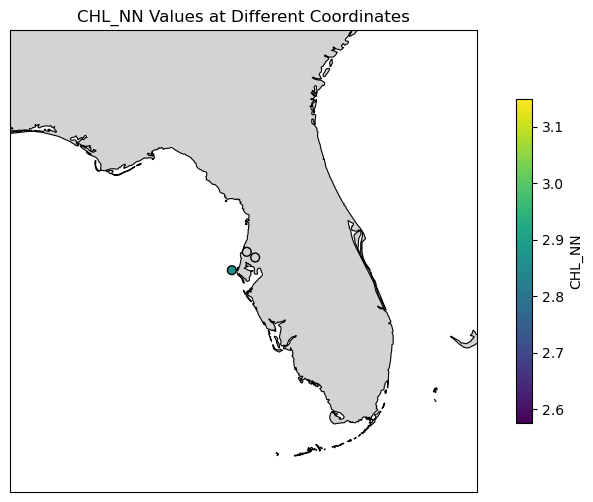

In [18]:
# Create a plot with Cartopy
fig, ax = plt.subplots(
    figsize=(10, 6),
    subplot_kw={"projection": ccrs.PlateCarree()}
)

# Add background features (land, borders, coastlines)
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# Adjust extent based on your gdf
minx, miny, maxx, maxy = gdf.total_bounds
ax.set_extent([minx - 4, maxx + 4, miny - 4, maxy + 4], crs=ccrs.PlateCarree())

# Scatter plot of points, colored by CHL_NN
sc = ax.scatter(
    gdf.geometry.x,
    gdf.geometry.y,
    c=gdf["CHL_NN"],
    cmap="viridis",
    s=40,
    edgecolor="k",
    transform=ccrs.PlateCarree()
)

# Add colorbar
cbar = plt.colorbar(sc, ax=ax, orientation="vertical", shrink=0.7)
cbar.set_label("CHL_NN")

# Titles and labels
plt.title("CHL_NN Values at Different Coordinates")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()


## 7. Take home messages

- The SNAP pixel extraction (PixEx) operator can be run with the EOCanvas to sample pixel values at custom locations.
- Sampling points from a pandas DataFrame can be added to the SNAP graph before the process is submitted.
- Missing values are usually caused by flagged pixels (e.g. clouds, land or low quality), so check the flags before you use the values.

<hr>

[View on GitHub](https://github.com/wekeo) | 
[Visit WEkEO](https://wekeo.copernicus.eu) | [Run Notebooks on the WEkEO Workspace](https://jupyterhub.prod.wekeo2.eu/) | 
[Contact helpdesk for support](mailto:support@wekeo.eu)